# Librerias

In [1]:
import io
import os
import cv2
import time
import numpy as np
import pickle
import subprocess
import re
import shutil
import glob
import matplotlib
import matplotlib.pyplot as plt
import plotly
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy.spatial.transform import Rotation as rotation
import requests

pio.renderers.default = "notebook_connected"

# Configuramos la ruta para que use las fuentes recién instaladas
os.environ["QT_QPA_FONTDIR"] = "/usr/share/fonts/truetype/dejavu/"

%matplotlib inline

# Funciones auxiliares

In [2]:
def rotation_matrix_from_euler_angles(euler_angles):
    A,B,C=euler_angles
    # R=Rz(C) @ Ry(B) @ Rx(A)
    R=rotation.from_euler('xyz', [A,B,C], degrees=False).as_matrix()
    return R

def euler_angles_from_rotation_matrix(R):
    euler_angles=rotation.from_matrix(R).as_euler('xyz', degrees=False) 
    return euler_angles

In [3]:
def click_event_point(event, x, y, flags, params, img, original_img, points, numerate, alternate):
    circle_radius=10
    if event == cv2.EVENT_LBUTTONDOWN:
        # Agregamos
        color=(0,0,255) # Rojo (por defecto)
        count=len(points) + 1 
        if alternate:
            if len(points) % 2 == 0:
                color=(0,255,0) # Verde
                count=int((len(points) + 1) / 2) + 1 
            else:
                color=(0,0,255) # Rojo
                count=int((len(points) + 1) / 2)
        if numerate:
            cv2.putText(img, f'{count}', (int(x), int(y)), cv2.FONT_HERSHEY_SIMPLEX, 1.0, color, 2, cv2.LINE_AA)
        cv2.circle(img, center=(int(x), int(y)), radius=5, color=color, thickness=-1)
        cv2.imshow('image', img)
        points.append((x,y)) 
    if event == cv2.EVENT_RBUTTONDOWN:
        # Eliminamos
        i=0
        band=False
        while i < len(points):
            if np.linalg.norm(np.array(points[i]) - np.array([x,y])) < circle_radius:
                # El punto se encuentra dentro del circulo
                band=True
                break
            i+=1
        if band:
            if i % 2 == 0:
                # Es un punto izquierdo
                points.pop(i)
                points.pop(i)
            else:
                # Es un punto derecho
                points.pop(i - 1)
                points.pop(i - 1)
            for i in range(3):
                img[:,:,i]=original_img[:,:,i]
            temp=[]
            for i in range(len(points)):
                x,y=points[i]
                click_event_point(cv2.EVENT_LBUTTONDOWN, x, y, None, None, img, original_img, temp, numerate, alternate)
    if event == cv2.EVENT_MOUSEMOVE:
        # Mostramos circulo
        img_copy=img.copy()
        cv2.circle(img_copy, center=(int(x), int(y)), radius=circle_radius, color=(0,0,0), thickness=2)
        cv2.imshow('image', img_copy)

def points_from_image(img_bgr, points1, points2, numerate=True, alternate=False):
    img=img_bgr.copy()
    original_img=img_bgr.copy()
    h,w,_=img.shape
    points=[]  
    cv2.namedWindow("image", cv2.WINDOW_GUI_NORMAL)
    cv2.setWindowProperty("image", cv2.WND_PROP_FULLSCREEN, cv2.WINDOW_FULLSCREEN)
    cv2.imshow('image', img)
    cv2.setMouseCallback('image', lambda event, x, y, flags, params: click_event_point(event, x, y, flags, params, img, original_img, points, numerate, alternate))
    if points1 is not None and points2 is not None:
        N=points1.shape[0]
        for i in range(N):
            x1,y1=points1[i]
            x2,y2=points2[i]
            click_event_point(cv2.EVENT_LBUTTONDOWN, x1, y1, None, None, img, original_img, points, numerate, alternate)
            click_event_point(cv2.EVENT_LBUTTONDOWN, x2 + w / 2, y2, None, None, img, original_img, points, numerate, alternate)
    while True:
        k = cv2.waitKey(1) 
        if k == ord('q'): 
            break
    cv2.destroyAllWindows()
    cv2.waitKey(1) 
    return np.array(points)

def manual_corresponding_points(image_bgr_1, image_bgr_2, points1=None, points2=None):
    points=points_from_image(img_bgr=cv2.hconcat([image_bgr_1, image_bgr_2]), points1=points1, points2=points2, numerate=True, alternate=True)
    h,w,_=image_bgr_1.shape
    m=points.shape[0]
    points1=np.zeros((int(m / 2),2))
    points2=np.zeros((int(m / 2),2))
    for i in range(int(m / 2)):
        points1[i]=points[i * 2]
        points2[i]=points[i * 2 + 1] - np.array([w,0])
    return points1,points2

# Clases auxiliares

In [4]:
class PlotCamera():
    def __init__(self):
        pass

    # Grafico 3D con Plotly
    @staticmethod
    def plotly_figure(title=''):
        fig = go.Figure(data=[])
        fig.update_layout(
            scene=dict(
                xaxis_title='x',
                yaxis_title='y',
                zaxis_title='z',
                # xaxis = dict(nticks=None, range=[-1,1]),
                # yaxis = dict(nticks=None, range=[-1,1]),
                # zaxis = dict(nticks=None, range=[-1,1]),
                # aspectmode='cube',
                # aspectratio=dict(x=1, y=1, z=1),
                camera=dict(
                    eye=dict(x=1.5, y=-1.5, z=1.5) 
                )
            ),
            title=dict(
                text=title,
                font=dict(
                    family="Arial",
                    size=24,
                    color="red"
                ),
                x=0.5, 
                xanchor="center"
            ), 
            autosize=False,
            width=800, 
            height=500,
            margin=dict(l=40, r=40, b=40, t=40),
            showlegend=False,
            legend=dict(
                yanchor="top",
                y=0.99,
                xanchor="left",
                x=0.01,
                font=dict(
                    family="Courier",
                    size=14,
                    color="black"
                ),
                itemsizing="constant"
            )
        )
        return fig
    
    # Dibujar sistema de coordenadas 
    @staticmethod
    def plot_coordinate_system(fig, Tsm, tsm, text='', subprefix=''):
        axis_color=['red','green','blue']
        axis_name=['X','Y','Z']
        cs=np.array([[0,0,0,1],[1,0,0,1],[0,1,0,1],[0,0,1,1]]).T
        Hsm=np.concatenate([np.concatenate([Tsm, tsm], axis=1), np.array([[0,0,0,1]])], axis=0)
        ps=(Hsm @ cs)[0:3,:]
        # Puntos
        fig.add_scatter3d(
            x=ps[0,:], 
            y=ps[1,:], 
            z=ps[2,:], 
            mode='markers', 
            marker=dict(size=6, symbol="circle", color='black'),
        )
        # Nombre de los ejes
        for j in range(3):
            fig.add_scatter3d(
                x=[ps[0,1 + j]], 
                y=[ps[1,1 + j]], 
                z=[ps[2,1 + j]], 
                mode='text', 
                text=f'{axis_name[j]}<sub>{subprefix}</sub>'
            )
        # Texto
        fig.add_scatter3d(
            x=[ps[0,0]], 
            y=[ps[1,0]], 
            z=[ps[2,0]], 
            mode='text', 
            text=text,
        )
        # Lineas
        for j in range(3):
            fig.add_scatter3d(
                x=[ps[0,0],ps[0,j+1]], 
                y=[ps[1,0],ps[1,j+1]], 
                z=[ps[2,0],ps[2,j+1]], 
                mode='lines', 
                line=dict(width=5, color=axis_color[j])
            )
        return fig

    # Dibujar sistema de coordenadas de la camara
    @staticmethod
    def plot_camera_coordinate_systems(T21, t21, title=''):
        # Sistemas de coordenadas de las camaras
        fig=PlotCamera.plotly_figure(title=title)
        T1m=np.array([
            [0,0,1],
            [-1,0,0],
            [0,-1,0]
        ])
        t1m=np.zeros((3,1))
        fig=PlotCamera.plot_coordinate_system(fig, T1m, t1m, text='S.C. camara 1', subprefix='1')
        H1m=np.concatenate([np.concatenate([T1m, t1m], axis=1), np.array([[0,0,0,1]])], axis=0)
        H21=np.concatenate([np.concatenate([T21, t21], axis=1), np.array([[0,0,0,1]])], axis=0)
        H2m=H1m @ H21
        T2m=H2m[0:3,0:3]
        t2m=H2m[0:3,[3]]
        fig=PlotCamera.plot_coordinate_system(fig, T2m, t2m / 1000, text='S.C. camara 2', subprefix='2')
        return fig

    # Dibujar puntos 3D con respecto al sistema de coordenadas de la camara
    @staticmethod
    def plot_point_cloud(vcs, title="", text="S.C. camara", subprefix=""):
        fig=PlotCamera.plotly_figure(title=title)
        Tcm=np.array([
            [0,0,1],
            [-1,0,0],
            [0,-1,0]
        ])
        tcm=np.zeros((3,1))
        fig=PlotCamera.plot_coordinate_system(fig, Tcm, tcm, text, subprefix)
        # Puntos
        ps=Tcm @ vcs.T
        fig.add_scatter3d(
            x=ps[0,:], 
            y=ps[1,:], 
            z=ps[2,:], 
            mode='markers', 
            marker=dict(size=6, symbol="circle", color='black'),
        )
        return fig

In [5]:
# Clase para obtener puntos correspondientes 2D y 3D de un tablero de ajedrez y de un marcador ArUco.
# Sistema de coordenadas puntos 2D (OpenCV): X (derecha), Y (abajo)
# Sistema de coordenadas puntos 3D: X (abajo), Y (derecha), Z (arriba)
class Correspondences_2D_and_3D():
    # Diccionario para el marcador ArUco
    dict_aruco = dict({
    	"DICT_4X4_50" : cv2.aruco.DICT_4X4_50,
    	"DICT_4X4_100" : cv2.aruco.DICT_4X4_100,
    	"DICT_4X4_250" : cv2.aruco.DICT_4X4_250,
    	"DICT_4X4_1000" : cv2.aruco.DICT_4X4_1000,
    	"DICT_5X5_50" : cv2.aruco.DICT_5X5_50,
    	"DICT_5X5_100" : cv2.aruco.DICT_5X5_100,
    	"DICT_5X5_250" : cv2.aruco.DICT_5X5_250,
    	"DICT_5X5_1000" : cv2.aruco.DICT_5X5_1000,
    	"DICT_6X6_50" : cv2.aruco.DICT_6X6_50,
    	"DICT_6X6_100" : cv2.aruco.DICT_6X6_100,
    	"DICT_6X6_250" : cv2.aruco.DICT_6X6_250,
    	"DICT_6X6_1000" : cv2.aruco.DICT_6X6_1000,
    	"DICT_7X7_50" : cv2.aruco.DICT_7X7_50,
    	"DICT_7X7_100" : cv2.aruco.DICT_7X7_100,
    	"DICT_7X7_250" : cv2.aruco.DICT_7X7_250,
    	"DICT_7X7_1000" : cv2.aruco.DICT_7X7_1000,
    })

    def __init__(self):
        pass

    @staticmethod
    def points_2D_from_aruco_marker(image_bgr, aruco_type, aruco_id):
        if image_bgr is not None:
            dictionary=cv2.aruco.getPredefinedDictionary(Correspondences_2D_and_3D.dict_aruco[aruco_type])
            parameters=cv2.aruco.DetectorParameters()
            detector=cv2.aruco.ArucoDetector(dictionary, parameters)
            # Las detecciones se hacen en sentido de las manecillas del reloj
            corners,ids,rejected=detector.detectMarkers(image_bgr)
            if len(corners) > 0:
                res=np.where(ids == aruco_id)[0]
                if len(res) > 0:
                    pos=res[0]
                    points=corners[pos].squeeze()
                    return points  
        return None

    @staticmethod
    def points_3D_from_aruco_marker(square_size):
        T=np.eye(2) * square_size
        points=T @ np.array([[0,0,1,1],[0,1,1,0]])
        points=np.vstack([points, np.zeros((1, points.shape[1]))]).T
        return points
    
    @staticmethod
    def points_2D_from_chessboard(image_bgr, chessboard_dimensions, fast=True):
        if image_bgr is not None:
            image_gray=cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
            # Las detecciones se hacen de izquierda a derecha, de arriba a abajo
            # Corners shape: (N, 1, 2)
            ret,corners=cv2.findChessboardCorners(image_gray, chessboard_dimensions, None, flags=cv2.CALIB_CB_FAST_CHECK) if fast else cv2.findChessboardCorners(image_gray, chessboard_dimensions, None)
            if ret:
                points=corners.squeeze()
                return points
        return None

    @staticmethod
    def points_3D_from_chessboard(chessboard_dimensions, square_size):
        N=int(np.prod(chessboard_dimensions))
        w,h=chessboard_dimensions
        points=np.zeros((N,3))
        count=0
        T=np.eye(2) * square_size
        for x in range(h):
            for y in range(w):
                v=np.array([[x],[y]])
                u=(T @ v).flatten()
                points[count]=np.array([u[0],u[1],0])
                count+=1
        return points

    @staticmethod
    def correspondences_2D_and_3D_from_aruco_marker(image_bgr, aruco_type, aruco_id, square_size):
        points_2D=Correspondences_2D_and_3D.points_2D_from_aruco_marker(image_bgr=image_bgr, aruco_type=aruco_type, aruco_id=aruco_id)
        points_3D=Correspondences_2D_and_3D.points_3D_from_aruco_marker(square_size=square_size)
        return (points_2D,points_3D,True) if points_2D is not None and points_3D is not None else (None,None,False)

    @staticmethod
    def correspondences_2D_and_3D_from_chessboard(image_bgr, chessboard_dimensions, square_size, fast=True):
        points_2D=Correspondences_2D_and_3D.points_2D_from_chessboard(image_bgr=image_bgr, chessboard_dimensions=chessboard_dimensions, fast=fast)
        points_3D=Correspondences_2D_and_3D.points_3D_from_chessboard(chessboard_dimensions=chessboard_dimensions, square_size=square_size)
        return (points_2D,points_3D,True) if points_2D is not None and points_3D is not None else (None,None,False)

In [6]:
class PinholeCameraModel():
    def __init__(self):
        pass

    # Dado el modelo ideal, devuelve el punto 2D sin distorsion
    @staticmethod
    def projection_ideal_camera_model(vws, K, Q):
        us_=K @ Q @ np.concatenate([vws, np.ones((vws.shape[0],1))], axis=1).T
        us_=us_ / us_[-1,:]
        us=us_[[0,1],:].T
        return us
    
    # Dado el modelo no ideal, devuelve el punto 2D distorsionado
    @staticmethod
    def projection_non_ideal_camera_model(vws, K, Q, q):
        N=vws.shape[0]
        uds=np.zeros((N,2))
        k1,k2,p1,p2,k3=q.flatten()
        for i in range(N):
            vw_=np.concatenate([vws[[i],:].T, np.ones((1,1))], axis=0)
            vc=Q @ vw_
            xc,yc,zc=vc.flatten()
            vn=np.array([
                [xc / zc],
                [yc / zc]
            ])
            r=np.linalg.norm(vn)
            xn,yn=vn.flatten()
            d=np.array([
                [xn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + 2 * p1 * xn * yn + p2 * (r**2 + 2 * xn**2)],
                [yn * (k1 * r**2 + k2 * r**4 + k3 * r**6) + p1 * (r**2 + 2 * yn**2) + 2 * p2 * xn * yn]
            ])
            vnd=vn + d
            vnd_=np.concatenate([vnd, np.ones((1,1))], axis=0)
            ud_=K @ vnd_
            ud=ud_[[0,1],:]
            uds[i]=ud.flatten()
        return uds

    # Calcula puntos 3D con respecto a los sistemas de coordenadas de las camaras
    @staticmethod
    def estimate_cameras_3D_points(T21, t21, us_1, us_2, K_1, K_2):
        N=us_1.shape[0]
        vc1s=np.zeros((N,3))
        vc2s=np.zeros((N,3))
        K_1_inv=np.linalg.inv(K_1)
        K_2_inv=np.linalg.inv(K_2)
        for i in range(N):
            u_1=us_1[i]
            u_2=us_2[i]
            u_1_=np.hstack([u_1, 1])[:,None]
            u_2_=np.hstack([u_2, 1])[:,None]
            w_1_=K_1_inv @ u_1_
            w_2_=K_2_inv @ u_2_
            A=np.array([
                [np.linalg.norm(w_1_) ** 2, (- w_1_.T @ T21 @ w_2_)[0,0]],
                [(w_2_.T @ T21.T @ w_1_)[0,0], - np.linalg.norm(w_2_) ** 2]
            ])
            b=np.array([
                [(w_1_.T @ t21)[0,0]],
                [(w_2_.T @ T21.T @ t21)[0,0]]
            ])
            zcs=np.linalg.inv(A) @ b
            zc1,zc2=zcs.flatten()
            vc1=zc1 * w_1_
            vc2=zc2 * w_2_
            vc1s[i]=vc1.flatten()
            vc2s[i]=vc2.flatten()
        return vc1s,vc2s
    
    # Calcula puntos 3D a partir de puntos correspondientes en 2 camaras calibradas
    @staticmethod
    def estimate_world_3D_points(K_1, Q_1, K_2, Q_2, us_1, us_2):
            N=us_1.shape[0]
            vws=np.zeros((N,3))
            P_1=K_1 @ Q_1
            P_2=K_2 @ Q_2
            p11_1,p12_1,p13_1,p14_1,p21_1,p22_1,p23_1,p24_1,p31_1,p32_1,p33_1,p34_1=P_1.flatten(order='C')
            p11_2,p12_2,p13_2,p14_2,p21_2,p22_2,p23_2,p24_2,p31_2,p32_2,p33_2,p34_2=P_2.flatten(order='C')
            for n in range(N):
                x_1,y_1=us_1[n]
                x_2,y_2=us_2[n]
                A=np.array([
                      [p31_1 * x_1 - p11_1,p32_1 * x_1 - p12_1,p33_1 * x_1 - p13_1],
                      [p31_1 * y_1 - p21_1,p32_1 * y_1 - p22_1,p33_1 * y_1 - p23_1],
                      [p31_2 * x_2 - p11_2,p32_2 * x_2 - p12_2,p33_2 * x_2 - p13_2],
                      [p31_2 * y_2 - p21_2,p32_2 * y_2 - p22_2,p33_2 * y_2 - p23_2]
                ])
                b=np.array([
                      [p14_1 - p34_1 * x_1],
                      [p24_1 - p34_1 * y_1],
                      [p14_2 - p34_2 * x_2],
                      [p24_2 - p34_2 * y_2]
                ])
                h=np.linalg.inv(A.T @ A) @ A.T @ b
                vw=h.flatten()
                vws[n]=vw
            return vws
    
    # Calcula la matriz extrinseca de la camara 
    @staticmethod
    def calculate_Q(us_2D, vws_2D, K):
        # Homografia entre el plano de imagen y el plano del tablero
        H=PinholeCameraModel.calculate_homography(us_2D, vws_2D)
        h1,h2,h3=H[:,[0]],H[:,[1]],H[:,[2]]
        K_inv=np.linalg.inv(K)
        alpha=1/(np.linalg.norm(K_inv @ h1))
        twc=alpha * K_inv @ h3
        if twc[-1,0] < 0:
            alpha*=-1
            twc*=-1
        iwc=alpha * K_inv @ h1
        jwc=alpha * K_inv @ h2
        kwc=np.cross(iwc.flatten(),jwc.flatten())[:,None]
        Q=np.hstack([iwc,jwc,kwc,twc])
        return Q

    # Elimina la distorsion de los puntos distorsionados
    @staticmethod
    def undistorted_points(uds, K, q):
        # Obtenemos los puntos normalizados sin distorsion
        vns=cv2.undistortPoints(uds[:,None,:].astype('float32'), K, q)
        vns=vns.squeeze()
        vns_=np.concatenate([vns, np.ones((vns.shape[0],1))], axis=1)
        # Obtenemos los puntos sin distorsion sobre el plano de imagen 
        us_=(K @ vns_.T).T
        us=us_[:,[0,1]]
        return us

    # Elimina la distorsion de una imagen
    @staticmethod
    def undistorted_image_bgr(distorted_image_bgr, K, q):
        # Eliminamos la distorsion en la imagen
        return cv2.undistort(distorted_image_bgr, K, q, None, K)

    # Calcula una homografia
    # points1: (N,2)
    # points2: (N,2)
    @staticmethod
    def calculate_homography(points1, points2):
        # Descomposicion SVD de una matriz
        # u,s,vh=np.linalg.svd(A)
        # The rows of vh are the eigenvectors of A'A and the columns of u are the eigenvectors of AA'. 
        # In both cases the corresponding (possibly non-zero) eigenvalues are given by s**2.
        N=points1.shape[0]
        A=np.zeros((2 * N, 9))
        for i in range(N):
            x,y=points1[i]
            v_=np.hstack([points2[[i],:], np.ones((1,1))]).T
            A[2 * i:2 * (i + 1)]=np.vstack([
                np.hstack([v_.T, np.zeros((1,3)), -x * v_.T]), 
                np.hstack([np.zeros((1,3)), v_.T, -y * v_.T])
            ])
        u,s,vh=np.linalg.svd(A)
        H=np.reshape(vh[-1], (3,3), order='C')
        return H

In [7]:
"""
calibration_parameters
    - 'S'
    - 'chessboard'
        - 'dimensions'
        - 'size'
    - 'camera'
        - 'error'
        - 'K'
        - 'q'
        - 'Qs'
"""
class CameraTemplate():
    def __init__(self, name, opencv_id):
        self.name=name
        self.opencv_id=opencv_id
        self.calibration_parameters=None
        self.path_calibration_parameters=os.path.join(os.getcwd(), *['calibration parameters', self.name])

    # Sobreescribir este metodo si se requiere preprocesar la imagen
    def image_preprocessing(self, image_bgr):
        return image_bgr
        
    def print_information(self):
        print()
        print(f"Nombre: {self.name}")
        print(f"ID opencv: {self.opencv_id}")

    def load_calibration_parameters(self):
        # Ruta al archivo
        path=os.path.join(self.path_calibration_parameters, *['calibration_parameters.dat'])
        try:
            with open(path, "rb") as f:
                self.calibration_parameters=pickle.load(f)
                return True
        except (OSError, IOError) as e:
            self.calibration_parameters=None
            # raise Exception("La camara no esta calibrada :(")
        return False
    
    def print_calibration_parameters(self):
        if self.calibration_parameters is not None:
            S=self.calibration_parameters['S']
            chessboard_dimensions=self.calibration_parameters['chessboard']['dimensions']
            square_size=self.calibration_parameters['chessboard']['size']
            error=self.calibration_parameters['camera']['error']
            K=self.calibration_parameters['camera']['K']
            q=self.calibration_parameters['camera']['q']
            Qs=self.calibration_parameters['camera']['Qs']

            print(f'\nNumero de imagenes del tablero de ajedrez: {S}')
            print(f'\nDimensiones el tablero de ajedrez: {chessboard_dimensions}')
            print(f'\nTamaño de los cuadrados del tablero de ajedrez (en mm): {square_size}')
            print(f'\nError de reproyección RMS general: {error}')
            print(f'\nMatriz intrinseca: \n{K}')
            print(f'\nParametros de distorsion: \n{q}')
            print(f'\nMatrices extrinsecas: \n{Qs}')
    
    # Muestra la camara y toma una imagen 
    def show_camera(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        image_bgr=None
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de la camara
                        ret,image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr=self.image_preprocessing(image_bgr)
                            # Se muestra lo que captura la camara
                            cv2.imshow(self.name, image_bgr)
                            key=cv2.waitKey(1)
                            
                            # Condicion de parada
                            if key == ord('q'):
                                break 
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return image_bgr

    # Vista de dos camaras
    @staticmethod
    def cameras_view(camera_1, camera_2, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        image_bgr_1=None
        image_bgr_2=None
        # Abrimos las camaras
        cap1=cv2.VideoCapture(camera_1.opencv_id, apiPreference)
        cap2=cv2.VideoCapture(camera_2.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap1.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap1.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
            cap2.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap2.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap1.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        cap2.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(f"{camera_1.name} | {camera_2.name}")
        while failure_counter < max_number_of_failures:
            try:
                if cap1 is not None and cap2 is not None:
                    if cap1.isOpened() and cap2.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de cada camara
                        ret1, image_bgr_1=cap1.read()
                        ret2, image_bgr_2=cap2.read()
                        # Dimensiones: (height,width,deep)
                        if ret1 and ret2:
                            image_bgr_1=camera_1.image_preprocessing(image_bgr_1)
                            image_bgr_2=camera_2.image_preprocessing(image_bgr_2)
                            # Se muestra lo que capturan las camaras
                            cv2.imshow(f"{camera_1.name} | {camera_2.name}", cv2.hconcat([image_bgr_1, image_bgr_2]))
                            key=cv2.waitKey(1)
                            
                            # Condicion de parada
                            if key == ord('q'):
                                break 
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1    
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap1.release()
        cap2.release()
        cv2.destroyAllWindows()
        return image_bgr_1,image_bgr_2

    # Toma imagenes cada cierto tiempo
    @staticmethod
    def take_cameras_images(camera_1, camera_2, number_of_images, timer_time, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        # Abrimos las camaras
        cap1=cv2.VideoCapture(camera_1.opencv_id, apiPreference)
        cap2=cv2.VideoCapture(camera_2.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap1.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap1.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
            cap2.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap2.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap1.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        cap2.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(f"{camera_1.name} | {camera_2.name}")
        # Para guardar las iamgenes tomadas
        cameras_images=[]
        # Contador de imagenes
        count=1
        # Se inicializa el timer 
        start_t=time.time()
        end_t=time.time()
        while failure_counter < max_number_of_failures:
            try:
                if cap1 is not None and cap2 is not None:
                    if cap1.isOpened() and cap2.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de cada camara
                        ret1, image_bgr_1=cap1.read()
                        ret2, image_bgr_2=cap2.read()
                        # Dimensiones: (height,width,deep)
                        if ret1 and ret2:
                            image_bgr_1=camera_1.image_preprocessing(image_bgr_1)
                            image_bgr_2=camera_2.image_preprocessing(image_bgr_2)
                            text=f'Tiempo para la foto ({count}/{number_of_images}): {(timer_time - (end_t - start_t)):.2f}'
                            img_bgr=cv2.hconcat([image_bgr_1, image_bgr_2])
                            img_bgr=cv2.putText(img_bgr, text, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 3, cv2.LINE_AA)
                            # Se muestra lo que capturan las camaras
                            cv2.imshow(f"{camera_1.name} | {camera_2.name}", img_bgr)
                            key=cv2.waitKey(1)
                            
                            end_t=time.time()
                            # Condicion de parada
                            if key == ord('q') or count > number_of_images:
                                break 
                            # Se cumple el tiempo de guardar la imagen actual
                            if end_t - start_t >= timer_time:
                                cameras_images.append((image_bgr_1,image_bgr_2))
                                count+=1
                                start_t=end_t
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap1.release()
        cap2.release()
        cv2.destroyAllWindows()
        return cameras_images

In [8]:
class WifiCamera(CameraTemplate):
    def __init__(self, name, opencv_id):
        super().__init__(name, opencv_id)

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        image_bgr=cv2.rotate(image_bgr, cv2.ROTATE_90_CLOCKWISE)
        return image_bgr
        
    # # Cambiar la resolucion de la imagen
    # @staticmethod
    # def esp32_cam_change_resolution(esp32_IP, val=7):
    #     # Valores de configuración
    #     var = "framesize"
    #     # Construimos la URL
    #     URL = f"http://{esp32_IP}/control?var={var}&val={str(val)}"
    #     try:
    #         print(f"Enviando petición a: {URL}")
    #         # Realizamos la petición GET directa
    #         response = requests.get(URL, timeout=5)
    #         # Verifica si la petición fue exitosa
    #         if response.status_code == 200:
    #             print("¡Resolución cambiada con éxito!")
    #             print("Respuesta del servidor:", response.text)
    #         else:
    #             print(f"Error en el servidor. Código de estado: {response.status_code}")
    #     except requests.exceptions.RequestException as e:
    #         print(f"No se pudo conectar con el ESP32-CAM: {e}")

    # Configuracion inicial para el ESP32 CAM
    @staticmethod
    def esp32_cam_initial_configuration(esp32_IP):
        """
            - Cambiar resolucion 
            - Desactivar Balance de Blancos Automático (AWB)
            - Desactivar Control de Ganancia Automático (AGC)
            - Desactivar Control de Exposición Automático (AEC)
        """
        URL = f"http://{esp32_IP}/control"
        
        # Abrimos la sesión para mantener la conexión abierta y rápida
        with requests.Session() as sesion:
            try:
                # Añadimos un 'timeout' de 3 segundos para que Python no se quede esperando por siempre si la cámara se desconecta.

                # Cambiar resolucion
                res = sesion.get(URL, params={"var": "framesize", "val": 8}, timeout=3)
                # Lanza un error si el ESP32 responde con un fallo (ej: 404 o 500)
                res.raise_for_status() 
                
                # Desactivar Balance de Blancos
                res = sesion.get(URL, params={"var": "awb", "val": 0}, timeout=3)
                res.raise_for_status() 
                
                # Desactivar Ganancia
                res = sesion.get(URL, params={"var": "agc", "val": 0}, timeout=3)
                res.raise_for_status()
                
                # Desactivar Exposición
                res = sesion.get(URL, params={"var": "aec", "val": 0}, timeout=3)
                res.raise_for_status()
                
                print(f"[OK] Cámara {esp32_IP} configurada con éxito.")
    
            except requests.exceptions.Timeout:
                print(f"[ERROR] Tiempo de espera agotado con {esp32_IP}. ¿Está encendida?")
                
            except requests.exceptions.ConnectionError:
                print(f"[ERROR] No se pudo conectar a {esp32_IP}. Revisa la red WiFi o la dirección IP.")
                
            except requests.exceptions.RequestException as e:
                print(f"[ERROR] Ocurrió un fallo inesperado con la cámara {esp32_IP}: {e}")

        # URL = f"http://{esp32_IP}/control"
    
        # # Abrimos una sesión para reutilizar la conexión interna
        # with requests.Session() as sesion:
        #     # Se envían una tras otra de forma casi instantánea
        #     sesion.get(URL, params={"var": "framesize", "val": 8})
        #     sesion.get(URL, params={"var": "awb", "val": 0})
        #     sesion.get(URL, params={"var": "gain_ctrl", "val": 0})
        #     sesion.get(URL, params={"var": "aec", "val": 0})
        
        # for var,val in [("framesize","8"),("awb","0"),("gain_ctrl","0"),("aec","0")]:
        #     # Construimos la URL
        #     URL = f"http://{esp32_IP}/control?var={var}&val={val}"
        #     # Realizamos la petición GET directa
        #     response = requests.get(URL, timeout=5)
        #     # Verifica si la petición fue exitosa
        #     if response.status_code == 200:
        #         print("¡Resolución cambiada con éxito!")
        #     else:
        #         print(f"Error en el servidor. Código de estado: {response.status_code}")

In [9]:
class USBCamera(CameraTemplate):
    def __init__(self, name, opencv_id):
        super().__init__(name, opencv_id)

    # Sobrescritura del método
    def image_preprocessing(self, image_bgr):
        return image_bgr
        
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

# Seleccion de camaras

## Camara Wifi

In [23]:
apiPreference=cv2.CAP_ANY

esp32_IP="192.168.100.90" 
# Configuracion inicial
WifiCamera.esp32_cam_initial_configuration(esp32_IP=esp32_IP)
name=f"esp32_cam_{esp32_IP.split(".")[-1]}"
opencv_id=f"http://{esp32_IP}:81/stream"
camera_1=WifiCamera(name, opencv_id)

esp32_IP="192.168.100.91" 
# Configuracion inicial
WifiCamera.esp32_cam_initial_configuration(esp32_IP=esp32_IP)
name=f"esp32_cam_{esp32_IP.split(".")[-1]}"
opencv_id=f"http://{esp32_IP}:81/stream"
camera_2=WifiCamera(name, opencv_id)

[OK] Cámara 192.168.100.90 configurada con éxito.
[OK] Cámara 192.168.100.91 configurada con éxito.


## Camara USB

In [10]:
apiPreference=cv2.CAP_V4L

name,opencv_id=USBCamera.select_camera()
camera_1=USBCamera(name, opencv_id)

name,opencv_id=USBCamera.select_camera()
camera_2=USBCamera(name, opencv_id)


****************************************************************************************************

Camaras disponibles: 
	 1)  ('USB PHY 2.0: USB CAMERA', '/dev/video2')
	 2)  ('HX-USB Camera: HX-USB Camera', '/dev/video4')
	 3)  ('EasyCamera: EasyCamera', '/dev/video0')


Elige una camara:  1



****************************************************************************************************

Camaras disponibles: 
	 1)  ('USB PHY 2.0: USB CAMERA', '/dev/video2')
	 2)  ('HX-USB Camera: HX-USB Camera', '/dev/video4')
	 3)  ('EasyCamera: EasyCamera', '/dev/video0')


Elige una camara:  2


# Informacion de las camaras

In [24]:
camera_1.print_information()
camera_2.print_information()


Nombre: esp32_cam_90
ID opencv: http://192.168.100.90:81/stream

Nombre: esp32_cam_91
ID opencv: http://192.168.100.91:81/stream


# Vista de las camaras

In [25]:
_,_=CameraTemplate.cameras_view(camera_1, camera_2, max_number_of_failures=100, apiPreference=apiPreference)

# Cargar parametros de calibracion

Los parametros de calibracion deben estar en el siguiente directorio:
**./calibration parameters/\<camera name>**

In [14]:
for i,camera in enumerate([camera_1, camera_2]):
    if camera.load_calibration_parameters():
        print(f"Los parametros de calibracion de la camara {i + 1} se cargaron correctamente")
    else:
        print(f"Hubo un error al intentar cargar los parametros de calibracion de la camara {i + 1} :(")

Los parametros de calibracion de la camara 1 se cargaron correctamente
Los parametros de calibracion de la camara 2 se cargaron correctamente


In [15]:
K_1=camera_1.calibration_parameters['camera']['K']
q_1=camera_1.calibration_parameters['camera']['q']
K_2=camera_2.calibration_parameters['camera']['K']
q_2=camera_2.calibration_parameters['camera']['q']

# Configuracion marcador ArUco

In [16]:
# Configuracion del marcador ArUco
aruco_type='DICT_7X7_50'
aruco_id=0
square_size=145 # mm

# Estimaciones 3D

## Calculo de matrices extrinsecas

In [17]:
# Captura de imagenes
distorted_image_bgr_1,distorted_image_bgr_2=CameraTemplate.cameras_view(camera_1, camera_2, max_number_of_failures=100, apiPreference=apiPreference)
undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

# Correspondencias
us_1,vws_1,is_ok_1=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_1, aruco_type, aruco_id, square_size)
us_2,vws_2,is_ok_2=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_2, aruco_type, aruco_id, square_size)

Q_1=None
Q_2=None
if is_ok_1 and is_ok_2:
    # Matrices extrinsecas
    Q_1=PinholeCameraModel.calculate_Q(us_1, vws_1[:,[0,1]], K_1)
    Q_2=PinholeCameraModel.calculate_Q(us_2, vws_2[:,[0,1]], K_2)
else:
    print("Las matrices extrinsecas no se calcularon, intentar de nuevo")

print(Q_1)
print(Q_2)

[[ 1.26779205e-01  9.81517532e-01  1.49274516e-01 -1.90558841e+02]
 [ 9.83737457e-01 -8.85565159e-02 -1.45568962e-01 -1.15055475e+02]
 [-1.27230691e-01  1.63195598e-01 -9.76782686e-01  5.91247596e+02]]
[[ 1.10008202e-01  9.84846296e-01  6.85625089e-02 -1.12936120e+01]
 [ 9.74829976e-01 -8.11135100e-02 -2.00492983e-01 -5.07535166e+01]
 [-1.93919346e-01  8.64683994e-02 -9.68980843e-01  5.75615566e+02]]


## Seleccion de puntos correspondientes

In [18]:
us_1=None
us_2=None

In [19]:
# Seleccion de puntos correspondientes
# Seleccionar un punto a la izquierda y otro a la derecha
# Presionar "q" para salir
us_1,us_2=manual_corresponding_points(undistorted_image_bgr_1, undistorted_image_bgr_2, us_1, us_2)
print(us_1.shape)
print(us_2.shape)

(4, 2)
(4, 2)


## Calculo de puntos 3D

Los puntos 3D estan expresados con respecto al sistema de coordenadas del mundo (definido en el marcador ArUco) y estan en mm

In [20]:
vws=PinholeCameraModel.estimate_world_3D_points(K_1, Q_1, K_2, Q_2, us_1, us_2)
print(vws)

[[-8.62239778e-02  1.02664982e+00  1.08812988e+00]
 [-2.30416116e+00  1.45246104e+02 -5.17361114e+00]
 [ 1.43264445e+02  1.44260541e+02 -2.18884576e+00]
 [ 1.41955362e+02 -6.68562066e-01 -1.57424810e+01]]


# Calibracion sistema estereo

In [21]:
_,_=CameraTemplate.cameras_view(camera_1, camera_2, max_number_of_failures=100, apiPreference=apiPreference)

In [23]:
cameras_images=CameraTemplate.take_cameras_images(camera_1, camera_2, number_of_images=30, timer_time=1, max_number_of_failures=100, apiPreference=apiPreference)

In [24]:
translations=[]
euler_angles=[]

for distorted_image_bgr_1,distorted_image_bgr_2 in cameras_images:
    undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
    undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

    # Correspondencias
    us_1,vws_1,is_ok_1=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_1, aruco_type, aruco_id, square_size)
    us_2,vws_2,is_ok_2=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_2, aruco_type, aruco_id, square_size)
    
    if is_ok_1 and is_ok_2:
        # Matrices extrinsecas
        Q_1=PinholeCameraModel.calculate_Q(us_1, vws_1[:,[0,1]], K_1)
        Q_2=PinholeCameraModel.calculate_Q(us_2, vws_2[:,[0,1]], K_2)
    
        Hw1=np.concatenate([Q_1, np.array([[0,0,0,1]])], axis=0)
        Hw2=np.concatenate([Q_2, np.array([[0,0,0,1]])], axis=0)
        H21=Hw1 @ np.linalg.inv(Hw2)
        
        T21=H21[0:3,0:3]
        t21=H21[0:3,[3]]  
    
        translations.append(t21.flatten())
        euler_angles.append(euler_angles_from_rotation_matrix(T21).flatten())

translations=np.array(translations)
euler_angles=np.array(euler_angles)

print(translations.shape)
print(euler_angles.shape)

(19, 3)
(19, 3)


In [26]:
fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=("Traslaciones (cm)", "Angulos de Euler"),
)
fig.add_trace(
    go.Scatter3d(
        x=translations[:,0] / 10, # mm a cm 
        y=translations[:,1] / 10, # mm a cm 
        z=translations[:,2] / 10, # mm a cm 
        mode='markers', 
        marker=dict(size=6, symbol="circle", color='red'),
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter3d(
        x=euler_angles[:,0], 
        y=euler_angles[:,1], 
        z=euler_angles[:,2], 
        mode='markers', 
        marker=dict(size=6, symbol="circle", color='blue'),
    ),
    row=1,
    col=2,
)
fig.update_layout(
    title_text="", height=600, width=1000
)
fig.update_scenes(
    xaxis_title="X", yaxis_title="Y", zaxis_title="Z"
)
fig.show()

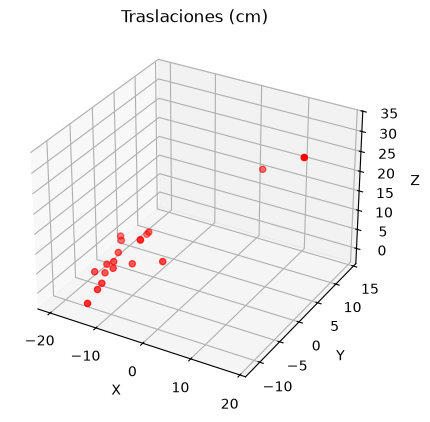

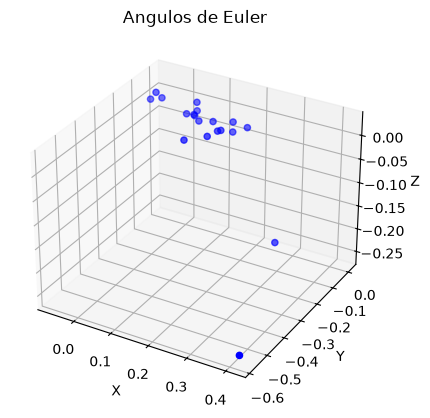

In [27]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(translations[:,0] / 10, translations[:,1] / 10, translations[:,2] / 10, c='red', marker='o')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title("Traslaciones (cm)")
plt.show()

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(euler_angles[:,0], euler_angles[:,1], euler_angles[:,2], c='blue', marker='o')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title("Angulos de Euler")
plt.show()

In [28]:
# Media
# T21=rotation_matrix_from_euler_angles(np.mean(euler_angles, axis=0))
# t21=np.mean(translations, axis=0)[:,None]

# Mediana
T21=rotation_matrix_from_euler_angles(np.median(euler_angles, axis=0))
t21=np.median(translations, axis=0)[:,None]

print(T21)
print(t21)

[[ 0.99806959  0.0102584  -0.06125249]
 [-0.01547576  0.99623332 -0.08532096]
 [ 0.06014651  0.08610418  0.99446894]]
[[-144.07774863]
 [ -18.29411072]
 [  10.03804514]]


In [29]:
fig=PlotCamera.plot_camera_coordinate_systems(T21, t21, title=f'Distancia aproximada: {(np.linalg.norm(t21) / 10):.2f} cm')
fig.show()

# Calculo de puntos 3D con respecto al sistema de coordenadas de las camaras

In [30]:
# Captura de imagenes
distorted_image_bgr_1,distorted_image_bgr_2=CameraTemplate.cameras_view(camera_1, camera_2, max_number_of_failures=100, apiPreference=apiPreference)
undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

In [31]:
us_1=None
us_2=None

In [32]:
# Seleccion de puntos correspondientes
# Seleccionar un punto a la izquierda y otro a la derecha
# Presionar "q" para salir
us_1,us_2=manual_corresponding_points(undistorted_image_bgr_1, undistorted_image_bgr_2, us_1, us_2)
print(us_1.shape)
print(us_2.shape)

(1, 2)
(1, 2)


In [ ]:
vc1s,vc2s=PinholeCameraModel.estimate_cameras_3D_points(T21, t21, us_1, us_2, K_1, K_2)
print(np.linalg.norm(vc1s, axis=1) / 10) # mm a cm
print(np.linalg.norm(vc2s, axis=1) / 10) # mm a cm

In [35]:
fig=PlotCamera.plot_point_cloud(vcs=vc1s / 1000, title="", text="S.C. camara 1", subprefix="1") ## mm a mts
fig.show()

In [36]:
fig=PlotCamera.plot_point_cloud(vcs=vc2s / 1000, title="", text="S.C. camara 2", subprefix="2") ## mm a mts
fig.show()

# Analisis con camara dual

In [10]:
class USBDualCamera():
    def __init__(self, name, opencv_id):
        self.name=name
        self.opencv_id=opencv_id
        self.calibration_parameters_1=None
        self.calibration_parameters_2=None
        self.path_calibration_parameters_1=os.path.join(os.getcwd(), *['calibration parameters', f"{self.name}-left"])
        self.path_calibration_parameters_2=os.path.join(os.getcwd(), *['calibration parameters', f"{self.name}-right"])
        
    def print_information(self):
        print()
        print(f"Nombre: {self.name}")
        print(f"ID opencv: {self.opencv_id}")

    def load_calibration_parameters(self):
        try:
            with open(os.path.join(self.path_calibration_parameters_1, *['calibration_parameters.dat']), "rb") as f:
                self.calibration_parameters_1=pickle.load(f)
            with open(os.path.join(self.path_calibration_parameters_2, *['calibration_parameters.dat']), "rb") as f:
                self.calibration_parameters_2=pickle.load(f)
            return self.calibration_parameters_1 is not None and self.calibration_parameters_2 is not None
        except (OSError, IOError) as e:
            self.calibration_parameters_1=None
            self.calibration_parameters_2=None
        return False
    
    def print_calibration_parameters(self):
        if self.calibration_parameters_1 is not None and self.calibration_parameters_2 is not None:
            for name,calibration_parameters in [("left", self.calibration_parameters_1), ("right", self.calibration_parameters_2)]:
                S=calibration_parameters['S']
                chessboard_dimensions=calibration_parameters['chessboard']['dimensions']
                square_size=calibration_parameters['chessboard']['size']
                error=calibration_parameters['camera']['error']
                K=calibration_parameters['camera']['K']
                q=calibration_parameters['camera']['q']
                Qs=calibration_parameters['camera']['Qs']
                print(f'\n({name}) Numero de imagenes del tablero de ajedrez: {S}')
                print(f'\n({name}) Dimensiones el tablero de ajedrez: {chessboard_dimensions}')
                print(f'\n({name}) Tamaño de los cuadrados del tablero de ajedrez (en mm): {square_size}')
                print(f'\n({name}) Error de reproyección RMS general: {error}')
                print(f'\n({name}) Matriz intrinseca: \n{K}')
                print(f'\n({name}) Parametros de distorsion: \n{q}')
                print(f'\n({name}) Matrices extrinsecas: \n{Qs}')
    
    # Muestra las camaras y toma una imagen 
    def show_cameras(self, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        image_bgr_1=None
        image_bgr_2=None
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual de la camara
                        ret,image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr_1,image_bgr_2=USBDualCamera.split_image(image_bgr)
                            # Se muestra lo que captura la camara
                            cv2.imshow(self.name, cv2.hconcat([image_bgr_1, image_bgr_2]))
                            key=cv2.waitKey(1)
                            
                            # Condicion de parada
                            if key == ord('q'):
                                break 
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return image_bgr_1,image_bgr_2

    # Toma imagenes cada cierto tiempo
    def take_cameras_images(self, number_of_images, timer_time, max_number_of_failures=100, apiPreference=cv2.CAP_ANY, frame_width=None, frame_height=None):
        failure_counter=0
        # Abrimos la camara
        cap=cv2.VideoCapture(self.opencv_id, apiPreference)
        # Cambiar resolucion
        if frame_width is not None and frame_height is not None:
            cap.set(cv2.CAP_PROP_FRAME_WIDTH, frame_width)
            cap.set(cv2.CAP_PROP_FRAME_HEIGHT, frame_height)
        # Reducir el tamaño del buffer al mínimo 
        cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        # Asignamos un nombre a la ventana
        cv2.namedWindow(self.name)
        # Para guardar las iamgenes tomadas
        cameras_images=[]
        # Contador de imagenes
        count=1
        # Se inicializa el timer 
        start_t=time.time()
        end_t=time.time()
        while failure_counter < max_number_of_failures:
            try:
                if cap is not None:
                    if cap.isOpened():
                        # Reiniciamos contador de fracasos
                        failure_counter=0
                        # Captura de la imagen actual 
                        ret, image_bgr=cap.read()
                        # Dimensiones: (height,width,deep)
                        if ret:
                            image_bgr_1,image_bgr_2=USBDualCamera.split_image(image_bgr)                        
                            text=f'Tiempo para la foto ({count}/{number_of_images}): {(timer_time - (end_t - start_t)):.2f}'
                            img_bgr=cv2.hconcat([image_bgr_1, image_bgr_2])
                            img_bgr=cv2.putText(img_bgr, text, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 3, cv2.LINE_AA)
                            # Se muestra lo que capturan las camaras
                            cv2.imshow(self.name, img_bgr)
                            key=cv2.waitKey(1)
                            
                            end_t=time.time()
                            # Condicion de parada
                            if key == ord('q') or count > number_of_images:
                                break 
                            # Se cumple el tiempo de guardar la imagen actual
                            if end_t - start_t >= timer_time:
                                cameras_images.append((image_bgr_1,image_bgr_2))
                                count+=1
                                start_t=end_t
                        else:
                            failure_counter+=1
                    else:
                        failure_counter+=1
                else:
                    failure_counter+=1
            except Exception as e:
                print("Exception: {}".format(e))
                break
        cap.release()
        cv2.destroyAllWindows()
        return cameras_images

    @staticmethod
    def split_image(image_bgr):
        h,w,d=image_bgr.shape
        wc=w // 2
        image_bgr_1=image_bgr[:, :wc, :]
        image_bgr_2=image_bgr[:, wc:, :]
        return image_bgr_1,image_bgr_2
    
    # Seleccionar una camara
    @staticmethod
    def select_camera():
        camera_information=None
        # Camaras conectadas via USB 
        # Cada elemento de la lista cuenta con: (Nombre de la camara, Ruta de la camara)
        camera_information_list=USBDualCamera.get_camera_information_list()
        while camera_information is None:
            print('\n' + 100 * '*')
            print('\nCamaras disponibles: ')
            for i in range(len(camera_information_list)):
                print(f'\t {i + 1}) ', camera_information_list[i])
            option=input('Elige una camara: ')
            if int(option) > 0 and int(option) <= len(camera_information_list):
                camera_information=camera_information_list[int(option) - 1]
                break
        return camera_information
    
    # Obtener informacion de las camaras conectadas via USB
    @staticmethod
    def get_camera_information_list():
        camera_information_list=[]
        res=subprocess.run(["v4l2-ctl", "--list-devices"], capture_output=True, text=True)
        res_split=res.stdout.split("\n\n")[0:-1]
        pattern = "video[0-9]{1}"
        for r in res_split:
            r_split=r.split("\n\t")
            if len(re.findall(pattern, r_split[1]))>0:
                camera_name=r_split[0].split("(")[0].strip() 
                camera_path=r_split[1]
                camera_information_list.append((camera_name, camera_path))
        return camera_information_list

## Seleccion de camara

In [11]:
frame_width=1280
frame_height=480
apiPreference=cv2.CAP_V4L

name,opencv_id=USBDualCamera.select_camera()
dual_camera=USBDualCamera(name, opencv_id)


****************************************************************************************************

Camaras disponibles: 
	 1)  ('USB Camera: USB Camera', '/dev/video0')
	 2)  ('EasyCamera: EasyCamera', '/dev/video2')


Elige una camara:  1


## Informacion de la camara

In [12]:
dual_camera.print_information()


Nombre: USB Camera: USB Camera
ID opencv: /dev/video0


## Vista de las camaras

In [13]:
image_bgr_1,image_bgr_2=dual_camera.show_cameras(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

## Cargar parametros de calibracion

Los parametros de calibracion deben estar en el siguiente directorio:
**./calibration parameters/\<camera name>**

In [14]:
if dual_camera.load_calibration_parameters():
    print(f"Los parametros de calibracion de las camaras se cargaron correctamente")
else:
    print(f"Hubo un error al intentar cargar los parametros de calibracion de las camaras :(")

Los parametros de calibracion de las camaras se cargaron correctamente


In [15]:
K_1=dual_camera.calibration_parameters_1['camera']['K']
q_1=dual_camera.calibration_parameters_1['camera']['q']
K_2=dual_camera.calibration_parameters_2['camera']['K']
q_2=dual_camera.calibration_parameters_2['camera']['q']

## Configuracion marcador ArUco

In [16]:
# Configuracion del marcador ArUco
aruco_type='DICT_7X7_50'
aruco_id=0
square_size=145 # mm

## Estimaciones 3D

### Calculo de matrices extrinsecas

In [17]:
# Captura de imagenes
distorted_image_bgr_1,distorted_image_bgr_2=dual_camera.show_cameras(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)
undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

# Correspondencias
us_1,vws_1,is_ok_1=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_1, aruco_type, aruco_id, square_size)
us_2,vws_2,is_ok_2=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_2, aruco_type, aruco_id, square_size)

Q_1=None
Q_2=None
if is_ok_1 and is_ok_2:
    # Matrices extrinsecas
    Q_1=PinholeCameraModel.calculate_Q(us_1, vws_1[:,[0,1]], K_1)
    Q_2=PinholeCameraModel.calculate_Q(us_2, vws_2[:,[0,1]], K_2)
else:
    print("Las matrices extrinsecas no se calcularon, intentar de nuevo")

print(Q_1)
print(Q_2)

[[-1.60264205e-01  9.68730140e-01 -1.91881176e-01 -4.50799034e+01]
 [ 7.88249176e-01  5.96996618e-03 -6.15275771e-01 -8.34228282e+01]
 [-5.94120039e-01 -2.47926744e-01 -7.64557507e-01  5.70705000e+02]]
[[-1.55128326e-01  9.55693266e-01 -1.85571937e-01 -1.31895756e+02]
 [ 7.65483775e-01 -1.33462634e-03 -6.34245129e-01 -7.47460815e+01]
 [-6.24475614e-01 -2.41335613e-01 -7.31360650e-01  5.57039662e+02]]


### Seleccion de puntos correspondientes

In [18]:
us_1=None
us_2=None

In [19]:
# Seleccion de puntos correspondientes
# Seleccionar un punto a la izquierda y otro a la derecha
# Presionar "q" para salir
us_1,us_2=manual_corresponding_points(undistorted_image_bgr_1, undistorted_image_bgr_2, us_1, us_2)
print(us_1.shape)
print(us_2.shape)

(4, 2)
(4, 2)


### Calculo de puntos 3D

Los puntos 3D estan expresados con respecto al sistema de coordenadas del mundo (definido en el marcador ArUco) y estan en mm

In [20]:
vws=PinholeCameraModel.estimate_world_3D_points(K_1, Q_1, K_2, Q_2, us_1, us_2)
print(vws)

[[-1.31919910e-10 -4.03580773e-11 -1.23495795e-11]
 [-3.40538362e+00  1.44015882e+02 -2.69705147e+00]
 [ 1.44343895e+02  1.44914994e+02 -2.83423912e-02]
 [ 1.44578480e+02  7.56357172e-03  3.69911075e-01]]


## Calibracion sistema estereo

In [17]:
image_bgr_1,image_bgr_2=dual_camera.show_cameras(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

In [18]:
cameras_images=dual_camera.take_cameras_images(number_of_images=30, timer_time=2, max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)

In [19]:
translations=[]
euler_angles=[]

for distorted_image_bgr_1,distorted_image_bgr_2 in cameras_images:
    undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
    undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

    # Correspondencias
    us_1,vws_1,is_ok_1=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_1, aruco_type, aruco_id, square_size)
    us_2,vws_2,is_ok_2=Correspondences_2D_and_3D.correspondences_2D_and_3D_from_aruco_marker(undistorted_image_bgr_2, aruco_type, aruco_id, square_size)
    
    if is_ok_1 and is_ok_2:
        # Matrices extrinsecas
        Q_1=PinholeCameraModel.calculate_Q(us_1, vws_1[:,[0,1]], K_1)
        Q_2=PinholeCameraModel.calculate_Q(us_2, vws_2[:,[0,1]], K_2)
    
        Hw1=np.concatenate([Q_1, np.array([[0,0,0,1]])], axis=0)
        Hw2=np.concatenate([Q_2, np.array([[0,0,0,1]])], axis=0)
        H21=Hw1 @ np.linalg.inv(Hw2)
        
        T21=H21[0:3,0:3]
        t21=H21[0:3,[3]]  
    
        translations.append(t21.flatten())
        euler_angles.append(euler_angles_from_rotation_matrix(T21).flatten())

translations=np.array(translations)
euler_angles=np.array(euler_angles)

print(translations.shape)
print(euler_angles.shape)

(25, 3)
(25, 3)


In [21]:
fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=("Traslaciones (cm)", "Angulos de Euler"),
)
fig.add_trace(
    go.Scatter3d(
        x=translations[:,0] / 10, # mm a cm 
        y=translations[:,1] / 10, # mm a cm 
        z=translations[:,2] / 10, # mm a cm 
        mode='markers', 
        marker=dict(size=6, symbol="circle", color='red'),
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter3d(
        x=euler_angles[:,0], 
        y=euler_angles[:,1], 
        z=euler_angles[:,2], 
        mode='markers', 
        marker=dict(size=6, symbol="circle", color='blue'),
    ),
    row=1,
    col=2,
)
fig.update_layout(
    title_text="", height=600, width=1000
)
fig.update_scenes(
    xaxis_title="X", yaxis_title="Y", zaxis_title="Z"
)
fig.show()

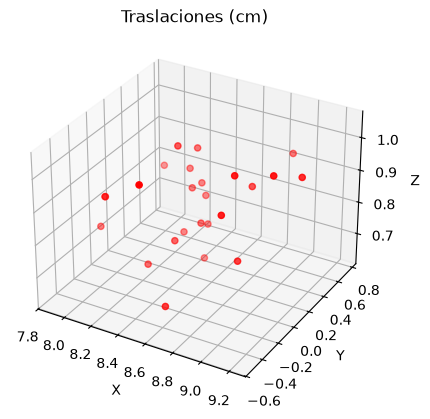

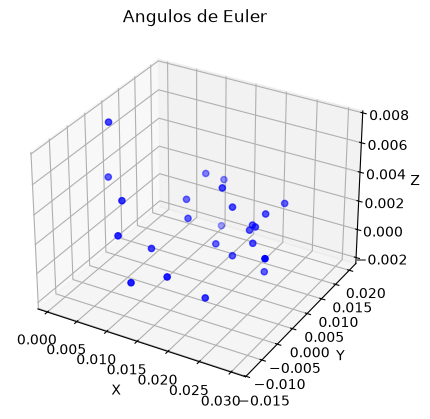

In [22]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(translations[:,0] / 10, translations[:,1] / 10, translations[:,2] / 10, c='red', marker='o')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title("Traslaciones (cm)")
plt.show()

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(euler_angles[:,0], euler_angles[:,1], euler_angles[:,2], c='blue', marker='o')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title("Angulos de Euler")
plt.show()

In [23]:
# Media
# T21=rotation_matrix_from_euler_angles(np.mean(euler_angles, axis=0))
# t21=np.mean(translations, axis=0)[:,None]

# Mediana
T21=rotation_matrix_from_euler_angles(np.median(euler_angles, axis=0))
t21=np.median(translations, axis=0)[:,None]

print(T21)
print(t21)

[[ 0.99997484 -0.0013418   0.0069649 ]
 [ 0.00145759  0.99986036 -0.01664719]
 [-0.00694159  0.01665693  0.99983717]]
[[84.34575736]
 [ 2.28439348]
 [ 8.3915336 ]]


In [25]:
fig=PlotCamera.plot_camera_coordinate_systems(T21, t21, title=f'Distancia aproximada: {(np.linalg.norm(t21) / 10):.2f} cm')
fig.show()

En la descripcion del producto se menciona que la distancia base es de 85 mm (8.5 cm)

## Calculo de puntos 3D con respecto al sistema de coordenadas de las camaras

In [26]:
# Captura de imagenes
distorted_image_bgr_1,distorted_image_bgr_2=dual_camera.show_cameras(max_number_of_failures=100, apiPreference=apiPreference, frame_width=frame_width, frame_height=frame_height)
undistorted_image_bgr_1=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_1, K_1, q_1)
undistorted_image_bgr_2=PinholeCameraModel.undistorted_image_bgr(distorted_image_bgr_2, K_1, q_1)

In [27]:
us_1=None
us_2=None

In [28]:
# Seleccion de puntos correspondientes
# Seleccionar un punto a la izquierda y otro a la derecha
# Presionar "q" para salir
us_1,us_2=manual_corresponding_points(undistorted_image_bgr_1, undistorted_image_bgr_2, us_1, us_2)
print(us_1.shape)
print(us_2.shape)

(4, 2)
(4, 2)


In [29]:
vc1s,vc2s=PinholeCameraModel.estimate_cameras_3D_points(T21, t21, us_1, us_2, K_1, K_2)
print(np.linalg.norm(vc1s, axis=1) / 10) # mm a cm
print(np.linalg.norm(vc2s, axis=1) / 10) # mm a cm

[43.83906194 45.19955194 44.75634772 43.08880311]
[44.38242794 43.01785203 42.97091963 44.07495654]


In [30]:
fig=PlotCamera.plot_point_cloud(vcs=vc1s / 1000, title="", text="S.C. camara 1", subprefix="1") ## mm a mts
fig.show()

In [31]:
fig=PlotCamera.plot_point_cloud(vcs=vc2s / 1000, title="", text="S.C. camara 2", subprefix="2") ## mm a mts
fig.show()